# Lesson 9 — Backpropagation: training a neural net by hand

Lesson 9 — Backpropagation: training a neural net by hand
=========================================================

GURU NOTE
---------
In Lesson 8 I HAND-SET the hidden weights. No one does that in practice — the
whole point is to LEARN them. Learning a net is the same idea as Lesson 4
(predict, measure error, step downhill), with one addition: the error has to be
pushed BACKWARDS through the layers so each weight knows its share of the blame.
That backward push is "backpropagation". It is just the chain rule from calculus,
applied layer by layer.

THE CHAIN RULE, IN ONE BREATH
-----------------------------
The output's error depends on the output-layer weights directly, and on the
hidden weights only THROUGH the hidden layer. So to get the hidden weights'
gradient you multiply: (how the loss changes with the hidden output) x (how the
hidden output changes with the hidden weights). "Multiply the slopes along the
path." That's the whole trick.

For our 2-layer net the gradients work out to (this is neural.fit_mlp, lines
125-135, verbatim):

    err = (p - y)              # output error   -- same (p-y) as logistic!
    gw2 = err.T @ h1           # output-layer weight gradient
    gb2 = err.sum(0)
    dh1 = err @ w2             # push error back through W2 (chain rule step)
    dz1 = dh1 * (z1 > 0)       # through ReLU: gradient flows only where it was ON
    gw1 = dz1.T @ x            # hidden-layer weight gradient
    gb1 = dz1.sum(0)

The magic line is `dz1 = dh1 * (z1 > 0)`: the derivative of relu is 1 where the
input was positive and 0 elsewhere. So gradient only flows through hidden units
that were actually active. That's it. We'll train the SAME XOR net from Lesson 8
and watch it discover its own hidden layer.

Run me:  python lessons/lesson_09_backprop.py

## Setup

These notebooks *import* the real code from `lessons/*.py` — one source of truth, no forked copies. This cell finds that folder.

In [1]:
import sys, pathlib
for base in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
    if (base / 'lessons' / '_util.py').exists():
        sys.path.insert(0, str(base / 'lessons'))
        print('lessons on path:', base / 'lessons'); break
else:
    raise RuntimeError('Open this notebook inside the xorguard-ml-course folder.')

lessons on path: /Users/anil/Documents/developer/vscodeworkspaces/xordev/xorguard-ml-course/lessons


## The key code (shown live from the source file)

Read it, then copy any function into a new cell and tweak it — the originals live in `lessons/lesson_09_backprop.py`.

In [2]:
import inspect
from lesson_09_backprop import fit_mlp
for fn in (fit_mlp,):
    print(inspect.getsource(fn)); print('-' * 72)

def fit_mlp(X, y, hidden: int = 8, epochs: int = 300, lr: float = 0.1,
            l2: float = 1e-4, batch: int = 64, fp_weight: float = 1.0,
            seed: int = 0, verbose: bool = True):
    """Train a 2-layer MLP with mini-batch gradient descent + backprop.

    This is a faithful, smaller sibling of neural.fit_mlp. Same forward pass, same
    backward pass, same class weighting. Only the sizes differ.
    """
    rng = np.random.default_rng(seed)
    n, d = X.shape
    # Small RANDOM init. If we started at zeros, every hidden unit would compute
    # the same thing forever ('symmetry') and never specialize. Randomness breaks
    # that. neural.py does the exact same thing.
    w1 = rng.normal(0, 0.5, (hidden, d))
    b1 = np.zeros(hidden)
    w2 = rng.normal(0, 0.5, (1, hidden))
    b2 = np.array([-0.5])

    # Class weights (Lesson 6), same formula as the repo.
    n_pos = max(float(np.sum(y >= 0.5)), 1.0)
    n_neg = max(float(np.sum(y < 0.5)), 1.0)
    sw = np.where(y >= 0.5,

## A picture

A real plot (matplotlib) in place of the terminal's ASCII. Re-run after changing inputs to build intuition.

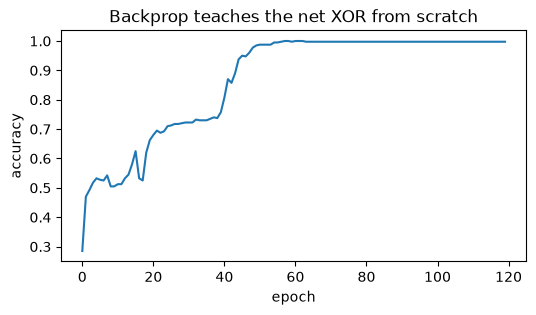

In [3]:
import numpy as np, matplotlib.pyplot as plt
from lesson_08_neural_networks import make_xor, forward, relu, accuracy
X, y = make_xor()
rng = np.random.default_rng(0); n, d = X.shape; hid = 8
w1 = rng.normal(0, 0.5, (hid, d)); b1 = np.zeros(hid)
w2 = rng.normal(0, 0.5, (1, hid)); b2 = np.array([-0.5])
accs = []; idx = np.arange(n)
for ep in range(120):
    rng.shuffle(idx)
    for s in range(0, n, 64):
        sl = idx[s:s + 64]; xb = X[sl]; yb = y[sl]
        z1 = xb @ w1.T + b1; h1 = relu(z1); p = 1 / (1 + np.exp(-(h1 @ w2.T + b2).ravel()))
        err = ((p - yb) / max(len(sl), 1))[:, None]
        gw2 = err.T @ h1; gb2 = err.sum(0)
        dz1 = (err @ w2) * (z1 > 0); gw1 = dz1.T @ xb; gb1 = dz1.sum(0)
        w1 -= 0.1 * gw1; b1 -= 0.1 * gb1; w2 -= 0.1 * gw2; b2 -= 0.1 * gb2
    accs.append(accuracy(y, forward(X, w1, b1, w2, b2)))
plt.figure(figsize=(6, 3)); plt.plot(accs)
plt.xlabel('epoch'); plt.ylabel('accuracy')
plt.title('Backprop teaches the net XOR from scratch'); plt.show()

## Run the full narrated lesson

This executes the same walkthrough as `python lessons/lesson_09_backprop.py`, printing each step with its result.

In [4]:
from lesson_09_backprop import main
main()


══════════════════════════════════════════════════
Lesson 9 — Backpropagation: training a net by hand
══════════════════════════════════════════════════

▸ First, TRUST the gradient. Analytic (backprop) vs numeric estimate:
    backprop says dL/dw2 = +0.012429
    numeric  says dL/dw2 = +0.012429
    difference = 1.83e-11  (tiny -> our backprop is correct)
    Always gradient-check a hand-derived backprop. This is the safety net.

▸ Now LEARN the XOR net that we hand-built in Lesson 8. Watch acc climb.
    Start: random weights, ~50% (clueless). Backprop finds the solution.

      epoch    1   acc=0.285
      epoch    5   acc=0.532
      epoch   25   acc=0.710
      epoch  100   acc=0.998
      epoch  300   acc=0.998

▸ Final result:
    trained MLP accuracy = 99.8%  (learned, not hand-set!)
    It rediscovered a hidden-layer solution to XOR on its own — no human
    picked those 8 hidden units' weights.

▸ Peek at what a hidden unit learned (its input weights):
      hidden unit 0: w

## Exercises

Try these in new cells below. Worked answers are in `solutions/lesson_09_solution.py`.

```
1. Set lr=2.0 and re-run. Does training destabilize? Then set lr=0.005. Does it
   crawl? Find an lr that reaches >95% in the fewest epochs.

2. Initialize w1 and w2 to ZEROS instead of random. Watch the net fail to learn
   and explain why in a comment (hint: 'symmetry' — every hidden unit stays
   identical). This is why random init matters.

3. Add gradient-checking for w1[0,0] (not just w2). Confirm the hidden-layer
   gradient is also correct. This is the exact tool that would have caught the
   real bug fixed in your repo's isolation-forest constant (see git log).
```

In [5]:
# your work here
